# matplotlib-資料視覺化

## 教學目標

這份教學的目標是介紹使用 `matplotlib` 繪圖的方法，並進一步對分析的資料進行視覺化。

## 適用對象

適用於有程式基礎，且擁有 python、`numpy`、`pandas` 基礎的學生。

若沒有先學過 Python，建議先補充 Python 入門語法。

若沒有先學過 `numpy`，請參考 [numpy-基本功能](./numpy-基本功能.ipynb) 教學。

若沒有先學過 `pandas`，請參考 [pandas-基本功能](./pandas-基本功能.ipynb) 教學。

## 原教材的執行時間與測試環境

以下是原教材的測試記錄，實際執行時間會因內容與環境而不同。

本教學全部執行時間約為 3.615583896636963 秒。

|測試環境|名稱|
|-|-|
|主機板|X570 AORUS ELITE|
|處理器|AMD Ryzen 7 3700X 8-Core Processor|
|記憶體|Kingston KHX3200C16D4/16GX|
|硬碟|Seagate ST1000DM003-1ER1|
|顯示卡|GeForce RTX 2080|
|作業系統|Ubuntu 18.04 LTS|

套件安裝與教材導覽請參考 [使用說明](./README.md)。

## 大綱與授課時間

本份約 **35 分鐘**，接著講 scikit-learn 約 **55 分鐘**，合計約 90 分鐘（含短問答）。

|段落|時間|課堂重點|
|---|---|---|
|從最簡單的折線圖開始|8 分鐘|x／y、plot／show、標籤與圖例、多條線、Figure／Axes 與子圖填空|
|根據問題選圖，讀取氣象資料|2 分鐘|資料欄位與缺失值|
|趨勢與分布|5 分鐘|折線圖、直方圖與 bins|
|特徵關係與類別數量|4 分鐘|散佈圖、顏色分組、類別筆數|
|小練習 6|4 分鐘|補完兩組氣溫直方圖|
|相關係數熱圖：範例與填空|7 分鐘|corr、heatmap、色階與相關性的解讀|
|課堂練習：分組箱型圖|5 分鐘|資料處理、分組與樣本數|

簡介與安裝快速帶過，套件請課前備妥。練習先讓學生短暫作答，再進行課堂討論。


## 簡介

根據 [matplotlib 官方網站](https://matplotlib.org/)（v3.4.2）：

> Matplotlib is a comprehensive library for creating static, animated, and interactive visualizations in Python.
>
> Matplotlib 是一個功能齊全的函式庫，能夠在 python 中繪製靜態圖表、動態圖表以及互動式圖表。

`matplotlib` 官方網站不只提供文件，同時也提供各種[繪圖使用範例](https://matplotlib.org/gallery/index.html)讓使用者可以選擇自己需要的繪圖功能。

而 `seaborn` 是一個基於 `matplotlib` 所開發的高階繪圖函式庫，根據 [seaborn 官方網站](https://seaborn.pydata.org/)（v0.11.1）：

> Seaborn is a Python data visualization library based on matplotlib.
>
> Seaborn 是一個基於 matplotlib 所開發的 python 資料視覺化函式庫。
>
> It provides a high-level interface for drawing attractive and informative statistical graphics.
>
> Seaborn 提供了高階程式界面，用於繪製引人入勝且內容豐富的統計圖表。

`seaborn` 的操作方法幾乎與 `matplotlib` 相同，同時也提供各種[繪圖使用範例](https://seaborn.pydata.org/examples/index.html)讓使用者可以選擇自己需要的繪圖功能。

## 安裝

透過 `pip` 安裝 `matplotlib`：

```sh
pip install matplotlib
```

透過 `pip` 安裝 `seaborn`：

```sh
pip install seaborn
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


## 0. 從最簡單的折線圖開始

以下四個例子取自或精簡自 `original/matplotlib-資料視覺化.ipynb` 的基本折線圖、圖例、多條線與多子圖範例。
先用少量數字看懂繪圖步驟，再換成氣象資料。

### 第一張圖：準備 x、y → plot → show

`x` 與 `y` 一一對應，長度必須相同。`plot` 將這些點依輸入順序連成線，`show` 顯示圖表。


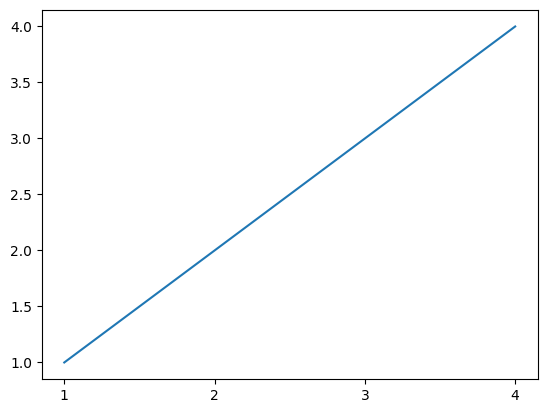

In [ ]:
x = [1, 2, 3, 4]
y = [1, 2, 3, 4]

plt.plot(x, y)
plt.show()


### 加上顏色、資料點與圖例

沿用上一張圖的 x、y，只增加閱讀圖表所需的資訊。
`marker` 設定資料點外觀；`label` 設定線的名稱，呼叫 `legend()` 才會顯示圖例。
`xlabel`、`ylabel` 與 `title` 分別設定兩軸名稱及標題。


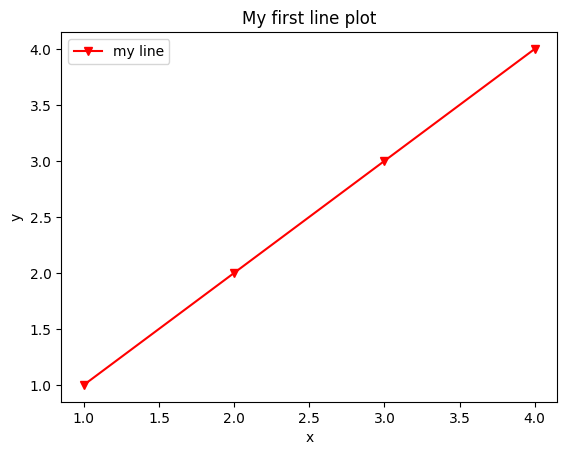

In [3]:
plt.plot(x, y, color='red', label='my line', marker='v')
plt.xlabel('x')
plt.ylabel('y')
plt.title('My first line plot')
plt.legend()
plt.show()


### 同一張圖畫兩條線

這個例子沿用原教材的 sine／cosine 資料。
在同一次 `show()` 前呼叫兩次 `plot()`，可把兩條線畫在同一張圖上。
觀察圖例如何對應線的顏色即可，無需推導三角函數。


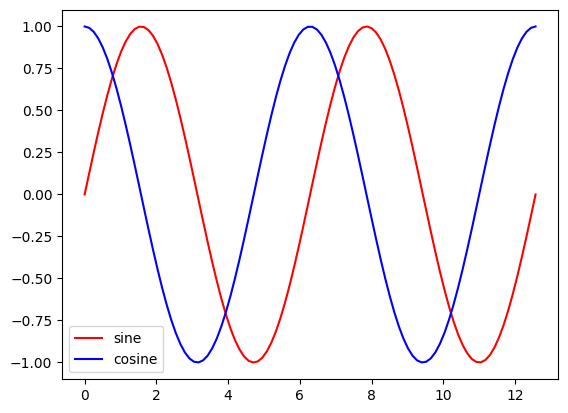

In [4]:
# 各式圖表 - 折線圖

# 準備 x 軸資料
x = np.linspace(
    0,         
    4 * np.pi,
    100
)
# 準備 y 軸資料
y1 = np.sin(x)             
# 準備 y 軸資料
y2 = np.cos(x)             

# 畫出 sine 折線圖
plt.plot(
    x, 
    y1,            
    color='red',
    label='sine'
)
# 畫出 cosine 折線圖
plt.plot(
    x, 
    y2,            
    color='blue',
    label='cosine'
)

# 使用圖例
plt.legend()               
# 繪製圖表
plt.show()                 

### 用子圖分開比較：Figure 與 Axes

將原教材的 2 × 3 子圖縮成 1 × 2，沿用上一格的 x、y1、y2。
`fig` 是整張畫布；`axes[0]`、`axes[1]` 是左右兩個繪圖區。
單張圖可以用 `plt.plot()`；要指定子圖時，改用該繪圖區的 `.plot()`。
`set_title()` 設定各子圖標題，`tight_layout()` 調整間距。


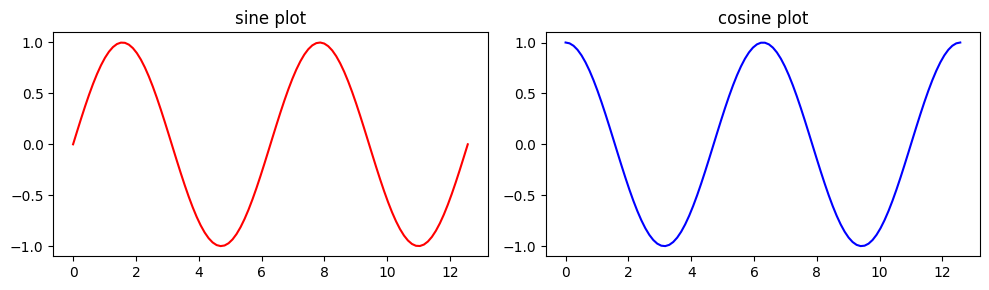

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(x, y1, color='red')
axes[0].set_title('sine plot')
axes[1].plot(x, y2, color='blue')
axes[1].set_title('cosine plot')
fig.tight_layout()
plt.show()


對應練習：[第 5 題](./exercises.ipynb#exercise-5)。


## 1. 先決定要回答什麼問題

|問題|圖表|判讀重點|
|---|---|---|
|數值如何隨時間變動？|折線圖|趨勢、突變、時間順序|
|數值集中在哪裡？|直方圖|分布、偏斜、可能的極端值|
|兩個特徵有關係嗎？|散佈圖|關聯、群聚、離群點；關聯不代表因果|
|各類別有幾筆？|長條圖|樣本數是否不均衡|
|數值特徵是否高度相關？|相關係數熱圖|可能重複的資訊；相關性不等於預測能力|

Matplotlib 負責一般繪圖，Seaborn 方便直接對表格繪製統計圖。

In [6]:
# 隨附的模擬資料；從 simplified 目錄執行。
df = pd.read_csv('./data/weather_sample.csv')
print("缺失筆數：\n", df.isna().sum())


缺失筆數：
 Day            0
Temperature    1
Humidity       0
Weather        0
Rain           0
dtype: int64


## 2. 趨勢與分布

氣溫缺失時，折線會中斷；直方圖忽略缺失值。
不為了讓圖連續就擅自填值。直方圖的 bins 會影響外觀，需配合樣本數解讀。
`bins=5` 代表自動分成 5 個區間，也可以傳入邊界清單，例如 `[15, 20, 25, 30]`；
比較不同組別時，使用相同邊界才方便比較。以下直方圖與多子圖整理自原繪圖教材。

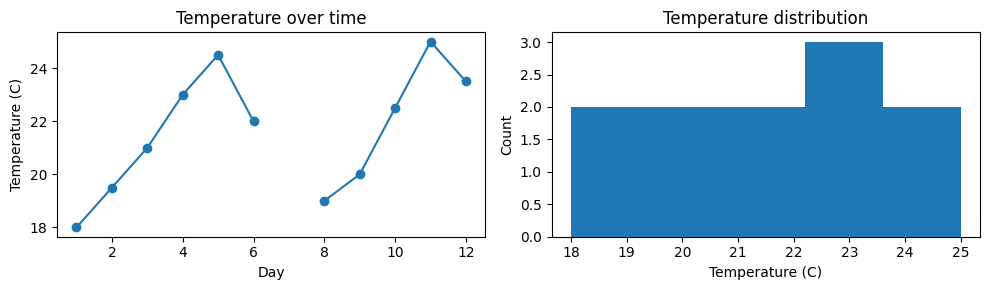

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].plot(df['Day'], df['Temperature'], marker='o')
axes[0].set(xlabel='Day', ylabel='Temperature (C)', title='Temperature over time')
axes[1].hist(df['Temperature'].dropna(), bins=5)
axes[1].set(xlabel='Temperature (C)', ylabel='Count', title='Temperature distribution')
fig.tight_layout()
plt.show()

**看圖後回答：**哪些天氣溫較高？缺資料的是哪一天？只有 12 筆模擬資料，能否支持季節性結論？

## 3. 特徵關係與類別數量

散佈圖用顏色區分是否下雨；它能幫助提出假設，不能取代模型驗證。
長條圖呈現每一類的樣本數，先確認資料是否偏向某一類。

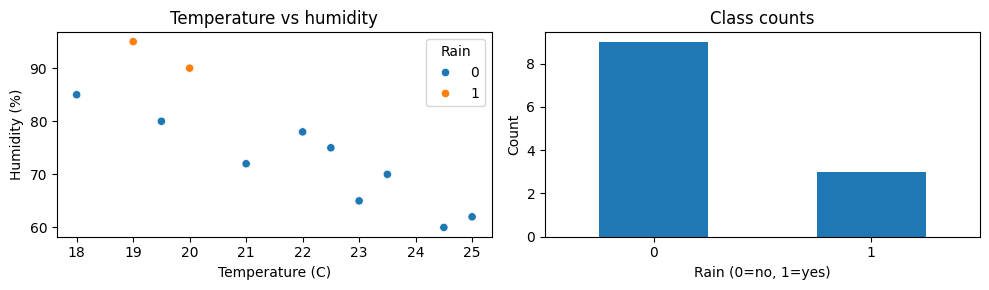

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.scatterplot(data=df, x='Temperature', y='Humidity', hue='Rain', ax=axes[0])
axes[0].set(title='Temperature vs humidity', xlabel='Temperature (C)', ylabel='Humidity (%)')
df['Rain'].value_counts().sort_index().plot.bar(ax=axes[1], rot=0)
axes[1].set(xlabel='Rain (0=no, 1=yes)', ylabel='Count', title='Class counts')
fig.tight_layout()
plt.show()

對應練習：[第 6 題](./exercises.ipynb#exercise-6)。


## 4. 相關係數熱圖

### 範例：氣溫與濕度的線性關係

先用 `.corr()` 計算相關係數，再交給 `sns.heatmap()` 顯示；熱圖本身不會計算相關性。

- 相關係數介於 −1 與 1：正值表示兩者傾向一起增加，負值表示一者增加時另一者傾向減少。
- 接近 ±1 表示較強的線性關聯，接近 0 不代表完全沒有關係；相關也不代表因果。
- `annot=True` 在格子內顯示數字，`fmt='.2f'` 保留兩位小數。
- `vmin=-1, vmax=1` 固定色階範圍，`center=0` 讓色階以 0 為中心。

本例含缺失值，pandas 以各欄位配對後的有效資料計算。對角線是欄位與自己比較，所以為 1；讀圖時主要看非對角線的格子。


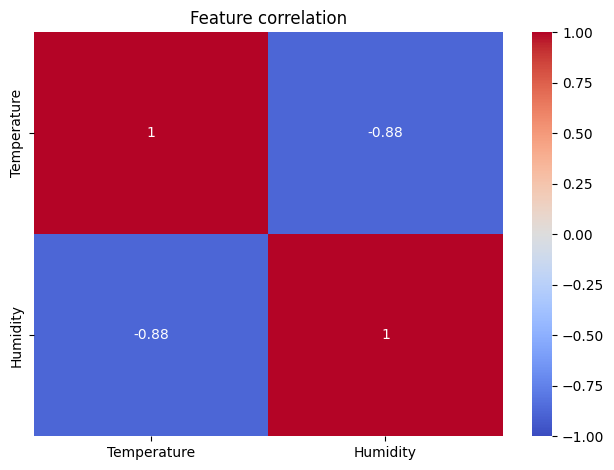

In [9]:
corr = df[['Temperature', 'Humidity']].corr()
print(corr)
sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0, cmap='coolwarm')
plt.title('Feature correlation')
plt.tight_layout()
plt.show()


對應練習：[第 7 題](./exercises.ipynb#exercise-7)。
